# 03 – CNN with transfer learning (MobileNetV2)

The colour baseline (notebook 02) only knows *which colours* appear in a photo. Defects such as an unsealed lid or a twisted rasher are about **shape and position**, which a convolutional neural network (CNN) can see.

**Approach – transfer learning:** start from MobileNetV2 pre-trained on ImageNet (1.2 million everyday photos), replace its last layer with a 2-output layer (PASS, FAIL) and fine-tune the whole network on our training photos. Details and reasons are in `src/rasher_inspection/cnn.py`.

**Experiment – input resolution:** notebook 01 showed that ~15% of defects shrink below 10 px if photos are resized to 224 px wide. We train the same model at **224 px** and **448 px** wide and compare accuracy against computation (FLOPs, time per photo).

**Before the full run:** leave `QUICK_RUN = True` and run all cells once. It trains on 300 photos for 1 epoch to check that everything works and to estimate the time. Then set `QUICK_RUN = False` and run all cells again.

In [ ]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

sys.path.insert(0, str(Path("..") / "src"))
from rasher_inspection.cnn import (best_device, build_model, class_weights, count_flops,
                                   count_parameters, fit, make_loader, predict, time_inference)
from rasher_inspection.data import load_dataset
from rasher_inspection.evaluate import format_summary, summarise

QUICK_RUN = False        # True = quick check (300 photos, 1 epoch); False = full experiment

DATA_DIR = Path("../data/raw")
RESULTS_DIR = Path("../results")
MODELS_DIR = Path("../models")    # trained weights (not uploaded to GitHub)
RESULTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

WIDTHS = [224, 448]     # input widths to compare
EPOCHS = 1 if QUICK_RUN else 8
BATCH_SIZE = 32         # used at 224 px; the 448 px run uses 8 (see below)
LEARNING_RATE = 3e-4
SEED = 0

device = best_device()
print("PyTorch", torch.__version__, "| device:", device)

data = load_dataset(DATA_DIR)
train_records = data["train"]
if QUICK_RUN:
    rng = np.random.default_rng(SEED)
    train_records = [train_records[i] for i in rng.choice(len(train_records), 300, replace=False)]
print({"train": len(train_records), "valid": len(data["valid"]), "test": len(data["test"])})

MODEL_COLOURS = {"CNN 224 px": "#6250d6", "CNN 448 px": "#e87ba4"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

PyTorch 2.14.1 | device: mps
{'train': 3349, 'valid': 120, 'test': 80}


## How training works

For each **epoch** (one pass over all training photos), in batches of 32 photos:

1. the network predicts PASS/FAIL scores,
2. the **loss** (weighted cross-entropy) measures how wrong it was – PASS mistakes are weighted ~4× because PASS photos are ~4× rarer,
3. **back-propagation** computes how each of the ~2.2 million weights should change, and the **Adam** optimiser nudges them (learning rate 0.0003 – small, so the useful pre-trained features are not destroyed).

After each epoch the model is scored on the validation set. The epoch with the **lowest validation loss** is kept (a form of early stopping). The test set is used only once, at the end.

In [11]:
def run_experiment(width):
    # Train and evaluate one model at the given input width.
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    print(f"\n=== Width {width} px ===")

    train_loader = make_loader(train_records, width, train=True, batch_size=BATCH_SIZE)
    valid_loader = make_loader(data["valid"], width, train=False, batch_size=BATCH_SIZE)
    test_loader = make_loader(data["test"], width, train=False, batch_size=BATCH_SIZE)

    model = build_model(pretrained=True).to(device)
    weights = class_weights([r.label for r in train_records])
    start = time.perf_counter()
    model, history = fit(model, train_loader, valid_loader, EPOCHS, LEARNING_RATE, weights, device)
    train_minutes = (time.perf_counter() - start) / 60

    summaries = {}
    for split, loader in (("valid", valid_loader), ("test", test_loader)):
        y_true, y_pred, _ = predict(model, loader, device)
        summaries[split] = summarise(y_true, y_pred)

    result = {
        **summaries,
        "history": history,
        "train_minutes": train_minutes,
        "parameters": count_parameters(model),
        "gflops_per_photo": count_flops(model, width) / 1e9,
        "ms_per_photo_device": time_inference(model, width, device),
        "ms_per_photo_cpu": time_inference(model, width, torch.device("cpu")),
        "device": str(device),
        "batch_size": BATCH_SIZE,
    }
    if not QUICK_RUN:
        torch.save(model.state_dict(), MODELS_DIR / f"mobilenetv2_{width}.pt")
    return result

results = {}

## Train at 224 px

In [12]:
results["CNN 224 px"] = run_experiment(224)
print()
print(format_summary("CNN 224 px – test set", results["CNN 224 px"]["test"]))

if QUICK_RUN:
    per_photo = results["CNN 224 px"]["history"][0]["seconds"] / len(train_records)
    full = per_photo * len(data["train"]) * 8 / 60
    print(f"\nEstimated full run: ~{full:.0f} min at 224 px and ~{3 * full:.0f} min at 448 px (8 epochs each)")


=== Width 224 px ===
epoch  1: train loss 0.624  valid loss 0.521  valid bal. acc 70.3%  (44 s)
epoch  2: train loss 0.474  valid loss 0.490  valid bal. acc 72.6%  (36 s)
epoch  3: train loss 0.390  valid loss 0.525  valid bal. acc 82.7%  (33 s)
epoch  4: train loss 0.315  valid loss 0.398  valid bal. acc 80.1%  (40 s)
epoch  5: train loss 0.254  valid loss 0.479  valid bal. acc 86.7%  (33 s)
epoch  6: train loss 0.218  valid loss 0.580  valid bal. acc 82.0%  (33 s)
epoch  7: train loss 0.157  valid loss 0.819  valid bal. acc 69.5%  (33 s)
epoch  8: train loss 0.128  valid loss 0.554  valid bal. acc 84.6%  (33 s)

CNN 224 px – test set   (caught 59, missed 9, passed 10, rejected 2)
  Balanced accuracy   85.0%   (95% CI 72.1% – 95.4%)
  Defects caught      86.8%   (95% CI 76.7% – 92.9%)
  Good trays passed   83.3%   (95% CI 55.2% – 95.3%)
  Accuracy            86.2%   (95% CI 77.0% – 92.1%)


## Train at 448 px

Twice the width and height means 4× the pixels. With a batch size of 32 the Mac (16 GB of memory shared between CPU and GPU) ran out of memory: memory pressure went red, the system started swapping to disk, and epochs slowed from 87 s to 261 s. The run was stopped and repeated with a **batch size of 8**, which needs about a quarter of the memory per step.

Note: this means the two widths were also trained with different batch sizes, so the comparison is not perfectly controlled.

In [14]:
BATCH_SIZE = 8   # batch size 32 ran out of memory at 448 px on a 16 GB Mac

results["CNN 448 px"] = run_experiment(448)
print()
print(format_summary("CNN 448 px – test set", results["CNN 448 px"]["test"]))


=== Width 448 px ===
epoch  1: train loss 0.607  valid loss 0.455  valid bal. acc 78.2%  (91 s)
epoch  2: train loss 0.490  valid loss 0.444  valid bal. acc 79.9%  (84 s)
epoch  3: train loss 0.428  valid loss 0.384  valid bal. acc 83.9%  (85 s)
epoch  4: train loss 0.397  valid loss 0.447  valid bal. acc 82.2%  (85 s)
epoch  5: train loss 0.320  valid loss 0.588  valid bal. acc 76.3%  (98 s)
epoch  6: train loss 0.310  valid loss 0.450  valid bal. acc 84.8%  (90 s)
epoch  7: train loss 0.250  valid loss 0.437  valid bal. acc 78.8%  (87 s)
epoch  8: train loss 0.221  valid loss 0.524  valid bal. acc 83.2%  (87 s)

CNN 448 px – test set   (caught 52, missed 16, passed 11, rejected 1)
  Balanced accuracy   84.1%   (95% CI 73.4% – 91.8%)
  Defects caught      76.5%   (95% CI 65.1% – 85.0%)
  Good trays passed   91.7%   (95% CI 64.6% – 98.5%)
  Accuracy            78.8%   (95% CI 68.6% – 86.3%)


## Training curves

If the training loss keeps falling while the validation loss rises, the model is starting to memorise the training photos (**overfitting**); the kept epoch is marked with a dot.

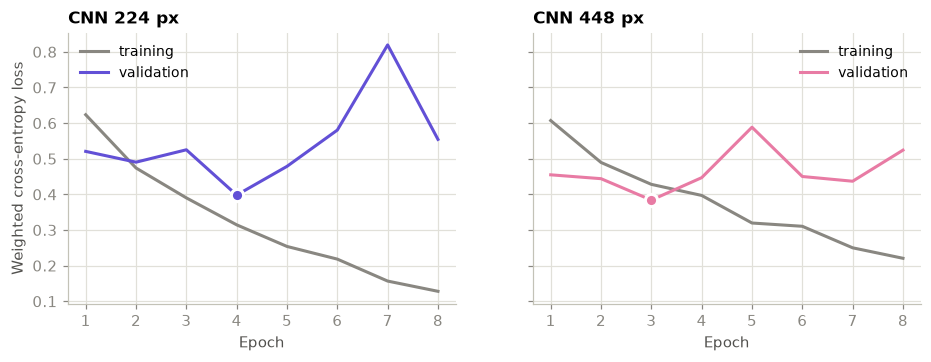

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    epochs = [h["epoch"] for h in r["history"]]
    ax.plot(epochs, [h["train_loss"] for h in r["history"]], color="#898781", linewidth=2, label="training")
    ax.plot(epochs, [h["valid_loss"] for h in r["history"]], color=MODEL_COLOURS[name], linewidth=2, label="validation")
    best = min(r["history"], key=lambda h: h["valid_loss"])
    ax.plot(best["epoch"], best["valid_loss"], "o", markersize=8, color=MODEL_COLOURS[name],
            markeredgecolor="white", markeredgewidth=2)
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("Weighted cross-entropy loss")
fig.savefig(RESULTS_DIR / "03_training_curves.png")
plt.show()

## Resolution experiment: accuracy vs computation

In [16]:
print(f"{'':<12}{'bal. acc (test)':>22}{'defects caught':>16}{'good passed':>13}"
      f"{'GFLOPs':>8}{'ms/photo ' + str(device):>16}{'ms/photo cpu':>14}{'train min':>11}")
for name, r in results.items():
    t = r["test"]
    lo, hi = t["balanced_accuracy"]["ci"]
    print(f"{name:<12}{t['balanced_accuracy']['value']:>8.1%} ({lo:.0%}–{hi:.0%})"
          f"{t['defects_caught']['value']:>16.1%}{t['good_passed']['value']:>13.1%}"
          f"{r['gflops_per_photo']:>8.2f}{r['ms_per_photo_device']:>16.1f}{r['ms_per_photo_cpu']:>14.1f}"
          f"{r['train_minutes']:>11.1f}")
print(f"\nParameters: {results['CNN 224 px']['parameters']:,} (the same at both widths)")

                   bal. acc (test)  defects caught  good passed  GFLOPs    ms/photo mps  ms/photo cpu  train min
CNN 224 px     85.0% (72%–95%)           86.8%        83.3%    0.47             9.6          51.5        4.8
CNN 448 px     84.1% (73%–92%)           76.5%        91.7%    1.82            10.1          74.9       11.8

Parameters: 2,226,434 (the same at both widths)


In [17]:
if not QUICK_RUN:
    with open(RESULTS_DIR / "03_cnn.json", "w") as f:
        json.dump(results, f, indent=2)
    print("Saved", RESULTS_DIR / "03_cnn.json")
else:
    print("Quick run finished – set QUICK_RUN = False and run all cells again for the real experiment.")

Saved ../results/03_cnn.json


## What this tells us

**1. Both CNNs are far better than the colour baseline.** Balanced accuracy on the test set rose from 69.6% (colour histogram) to 85.0% (224 px) and 84.1% (448 px). Seeing *shapes and positions*, not just colours, is what makes the difference.

**2. Higher resolution did not improve the model overall.** Balanced accuracy is practically the same at both widths, and the 95% intervals overlap almost completely. The 448 px model shifted the balance: it rejected fewer good trays (11 of 12 passed vs 10 of 12) but **missed more defects** (16 of 68 vs 9 of 68). For food packaging a missed defect is usually the more costly mistake.

**3. Higher resolution costs a lot more.**

| | 224 px | 448 px | ratio |
|---|---|---|---|
| Computation per photo | 0.47 GFLOPs | 1.82 GFLOPs | 3.8× |
| Training time (8 epochs) | 4.8 min | 11.8 min | 2.5× |
| Batch size that fits in 16 GB | 32 | 8 | – |
| Time per photo, CPU | 51 ms | 75 ms | 1.5× |
| Time per photo, Apple GPU (batch of 1) | 9.6 ms | 10.1 ms | ≈1× |

On the GPU both sizes take about 10 ms: with one photo at a time, the time is dominated by the fixed overhead of launching each of the network's many small GPU operations, not by the arithmetic, so the FLOP count does not predict the speed. On the CPU the extra arithmetic does show. Even on a CPU, ~50 ms per photo means about 20 photos per second.

**4. The models start to overfit after 3–4 epochs.** Training loss keeps falling, but validation loss is lowest at epoch 4 (224 px) and epoch 3 (448 px) and then rises (see the training curves). Keeping the best epoch (early stopping) protects against this; simply training longer would not help.

**Recommendation:** use the **224 px model** – the same overall accuracy, more defects caught, and about a quarter of the computation.

**Limitations of this experiment:** each model was trained once (one random seed), so differences of a few percentage points could change on a re-run; the two widths used different batch sizes; and the test set has only 12 PASS photos, so "good trays passed" moves 8 points per photo.